In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import urllib.request

%matplotlib inline


dataset = "./diabetes2.csv"


df = pd.read_csv(dataset)
#df
print(df.columns)
#print(f"Dataset loaded: {df.shape[0]} rows, {df.shape[1]} columns")
df.describe()

Index(['Unnamed: 0', 'Diabetes_012', 'HighBP', 'HighChol', 'CholCheck', 'BMI',
       'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits',
       'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost',
       'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age',
       'Education', 'Income'],
      dtype='object')


,Unnamed: 0,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
count,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,...,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000
mean,126839.500000,0.296921,0.429001,0.424121,0.962670,28.382364,0.443169,0.040571,0.094186,0.756544,...,0.951053,0.084177,2.511392,3.184772,4.242081,0.168224,0.440342,57.138127,5.050434,6.053875
std,73231.252481,0.698160,0.494934,0.494210,0.189571,6.608694,0.496761,0.197294,0.292087,0.429169,...,0.215759,0.277654,1.068477,7.412847,8.717951,0.374066,0.496429,15.323466,0.985774,2.071148
min,0.000000,0.000000,0.000000,0.000000,0.000000,12.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,21.000000,1.000000,1.000000
25%,63419.750000,0.000000,0.000000,0.000000,1.000000,24.000000,0.000000,0.000000,0.000000,1.000000,...,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,47.000000,4.000000,5.000000
50%,126839.500000,0.000000,0.000000,0.000000,1.000000,27.000000,0.000000,0.000000,0.000000,1.000000,...,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,57.000000,5.000000,7.000000
75%,190259.250000,0.000000,1.000000,1.000000,1.000000,31.000000,1.000000,0.000000,0.000000,1.000000,...,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,1.000000,67.000000,6.000000,8.000000
max,253679.000000,2.000000,1.000000,1.000000,1.000000,98.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,5.000000,30.000000,30.000000,1.000000,1.000000,82.000000,6.000000,8.000000


## Exercise 1: Fruit, Vegetables and Independence

Using `df['Fruits'] == 1` and `df['Veggies'] == 1`:

a. Compute the probability of eating fruit regularly.  
b. Compute the probability of eating vegetables regularly.  
c. Compute the probability of eating both fruit **and** vegetables regularly.  
d. Decide whether the two events appear independent.


In [12]:
# a, b and c

P_fruit = np.mean(df["Fruits"] == 1) # the probability of eating fruit regularly.

P_veg = np.mean(df["Veggies"] == 1) # the probability of eating vegetables regularly.

P_fruit_and_veg = np.mean((df["Fruits"] == 1) & (df["Veggies"] == 1)) # the probability of eating both fruit and vegetables regularly.

# If independent, P(Fruit and Veg) = P(Fruit) * P(Veg)
P_if_independent = P_fruit * P_veg



print(f"P(Fruit) = {P_fruit:.4f} ({100*P_fruit:.2f}%)")
print(f"P(Veggies) = {P_veg:.4f} ({100*P_veg:.2f}%)")
print(f"P(Fruit and Veggies) = {P_fruit_and_veg:.4f} ({100*P_fruit_and_veg:.2f}%)")
print(f"P(Fruit) * P(Veggies) = {P_if_independent:.4f}")

difference = abs(P_fruit_and_veg - P_if_independent)
print(f"Absolute difference = {difference:.4f}")

# d
if difference < 0.01:
    print("Conclusion: the events are approximately independent in this sample.")
else:
    print("Conclusion: the events do not appear independent in this sample.")


P(Fruit) = 0.6343 (63.43%)
P(Veggies) = 0.8114 (81.14%)
P(Fruit and Veggies) = 0.5626 (56.26%)
P(Fruit) * P(Veggies) = 0.5146
Absolute difference = 0.0479
Conclusion: the events do not appear independent in this sample.


## Exercise 2: Diabetes

a. What proportion of participants who eat both fruit and vegetables have diabetes?  
b. Can we say that eating fruit and vegetables reduces the risk of diabetes?


In [13]:
fruit_and_veg = (df["Fruits"] == 1) & (df["Veggies"] == 1)

P_diabetes_given_fruit_veg = np.mean(
    df.loc[fruit_and_veg, "Diabetes_012"] == 2
)

P_diabetes_overall = np.mean(df["Diabetes_012"] == 2)

print(
    f"P(Diabetes | Fruit and Veggies) = "
    f"{P_diabetes_given_fruit_veg:.4f} "
    f"({100*P_diabetes_given_fruit_veg:.2f}%)"
)
print(
    f"Overall P(Diabetes) = {P_diabetes_overall:.4f} "
    f"({100*P_diabetes_overall:.2f}%)"
)


P(Diabetes | Fruit and Veggies) = 0.1216 (12.16%)
Overall P(Diabetes) = 0.1393 (13.93%)


**Answer to (b):** No. Even if diabetes is less common among participants who regularly eat fruit and vegetables, this observational dataset only establishes an association. It does not establish that eating fruit and vegetables *causes* the reduction. Confounding variables such as age, income, exercise, BMI, and other health behaviours may affect both diet and diabetes risk.


## Exercise 3: Plotting

a. Plot the BMI histogram using **30 bins**.  
b. Is BMI normally distributed? Explain.


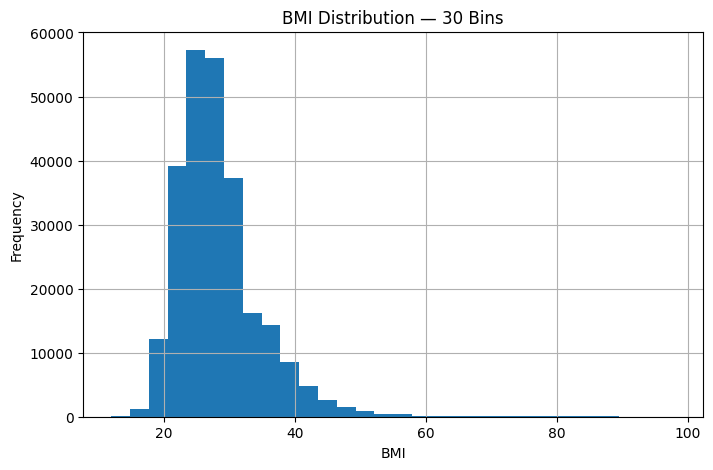

In [14]:
plt.figure(figsize=(8, 5))
plt.hist(df["BMI"], bins=30)
plt.grid()
plt.xlabel("BMI")
plt.ylabel("Frequency")
plt.title("BMI Distribution — 30 Bins")
plt.show()


**Answer to (b):** No. The BMI distribution is not well modelled by a normal distribution. The histogram is asymmetric and positively (right) skewed, with a relatively long upper-BMI tail. A normal distribution would be approximately symmetric and bell-shaped around its mean.


## Exercise 4: Expectations and Moments

Create BMI arrays for the lowest- and highest-income groups.

a. Compute variance **without** using `np.var` or `np.mean`.  
b. Compute skewness using

\[
\tilde{\mu}_3 =
E\left[\left(\frac{X-\mu}{\sigma}\right)^3\right].
\]


In [19]:
BMIofLowIncome = df[df["Income"] == 1]["BMI"].to_numpy()
BMIofHighIncome = df[df["Income"] == 8]["BMI"].to_numpy()

def variance_without_var_or_mean(x):
    n = len(x)
    mu = np.sum(x) / n
    variance = np.sum((x - mu) ** 2) / n
    return variance

low_variance = variance_without_var_or_mean(BMIofLowIncome)
high_variance = variance_without_var_or_mean(BMIofHighIncome)

print(f"Lowest-income BMI variance = {low_variance:.6f}")
print(f"Highest-income BMI variance = {high_variance:.6f}")


Lowest-income BMI variance = 66.649654
Highest-income BMI variance = 34.864573


In [20]:
def skewness_from_definition(x):
    n = len(x)
    mu = np.sum(x) / n
    variance = np.sum((x - mu) ** 2) / n
    sigma = np.sqrt(variance)

    skewness = np.sum(((x - mu) / sigma) ** 3) / n
    return skewness

low_skewness = skewness_from_definition(BMIofLowIncome)
high_skewness = skewness_from_definition(BMIofHighIncome)

print(f"Lowest-income BMI skewness = {low_skewness:.6f}")
print(f"Highest-income BMI skewness = {high_skewness:.6f}")


Lowest-income BMI skewness = 1.712143
Highest-income BMI skewness = 2.520959


## Exercise 5: Naive Bayes

a. What is the probability that a person has diabetes if they are **62 years old**, **not a smoker**, and have a **BMI of 20**?

b. What is the probability that a person is **over 50** if they have a **BMI of 20**, **have diabetes**, and **do not smoke**? Compute this using:

1. Naive Bayes, and
2. the full conditional distribution without the independence assumption.


In [21]:
# Part (a)
# Follow the lab's binary comparison: diabetic (2) versus non-diabetic (0).
dfD = df[df["Diabetes_012"] == 2]
dfNotD = df[df["Diabetes_012"] == 0]

# Likelihoods for BMI=20, Age=62 and non-smoker.
PB20_given_D = np.mean(dfD["BMI"] == 20)
PB20_given_notD = np.mean(dfNotD["BMI"] == 20)

PA62_given_D = np.mean(dfD["Age"] == 62)
PA62_given_notD = np.mean(dfNotD["Age"] == 62)

PNS_given_D = np.mean(dfD["Smoker"] == 0)
PNS_given_notD = np.mean(dfNotD["Smoker"] == 0)

# Priors.
PD = np.mean(df["Diabetes_012"] == 2)
PnotD = np.mean(df["Diabetes_012"] == 0)

score_D = PB20_given_D * PA62_given_D * PNS_given_D * PD
score_notD = PB20_given_notD * PA62_given_notD * PNS_given_notD * PnotD

P_D_given_features = score_D / (score_D + score_notD)

print(
    "Naive Bayes P(Diabetes | Age=62, BMI=20, Non-smoker) = "
    f"{P_D_given_features:.4f} ({100*P_D_given_features:.2f}%)"
)


Naive Bayes P(Diabetes | Age=62, BMI=20, Non-smoker) = 0.0418 (4.18%)


In [17]:
# Part (b): Naive Bayes
# Target class: Age > 50
over50 = df["Age"] > 50
not_over50 = ~over50

dfOver50 = df[over50]
dfNotOver50 = df[not_over50]

# Feature likelihoods conditioned on the target class.
PB20_given_over50 = np.mean(dfOver50["BMI"] == 20)
PB20_given_not_over50 = np.mean(dfNotOver50["BMI"] == 20)

PD_given_over50 = np.mean(dfOver50["Diabetes_012"] == 2)
PD_given_not_over50 = np.mean(dfNotOver50["Diabetes_012"] == 2)

PNS_given_over50 = np.mean(dfOver50["Smoker"] == 0)
PNS_given_not_over50 = np.mean(dfNotOver50["Smoker"] == 0)

P_over50 = np.mean(over50)
P_not_over50 = np.mean(not_over50)

score_over50 = (
    PB20_given_over50
    * PD_given_over50
    * PNS_given_over50
    * P_over50
)
score_not_over50 = (
    PB20_given_not_over50
    * PD_given_not_over50
    * PNS_given_not_over50
    * P_not_over50
)

P_over50_NB = score_over50 / (score_over50 + score_not_over50)

print(
    "Naive Bayes P(Age>50 | BMI=20, Diabetes, Non-smoker) = "
    f"{P_over50_NB:.4f} ({100*P_over50_NB:.2f}%)"
)


Naive Bayes P(Age>50 | BMI=20, Diabetes, Non-smoker) = 0.8214 (82.14%)


In [18]:
# Part (b): Full conditional distribution (no independence assumption)
condition = (
    (df["BMI"] == 20)
    & (df["Diabetes_012"] == 2)
    & (df["Smoker"] == 0)
)

matching_people = df[condition]
P_over50_full = np.mean(matching_people["Age"] > 50)

print(f"Number of matching participants = {len(matching_people)}")
print(
    "Full conditional P(Age>50 | BMI=20, Diabetes, Non-smoker) = "
    f"{P_over50_full:.4f} ({100*P_over50_full:.2f}%)"
)
print(f"Difference from Naive Bayes = {abs(P_over50_NB - P_over50_full):.4f}")


Number of matching participants = 115
Full conditional P(Age>50 | BMI=20, Diabetes, Non-smoker) = 0.9217 (92.17%)
Difference from Naive Bayes = 0.1004


### Naive Bayes comparison

The two answers need not be identical. The full conditional estimate uses only participants matching all three conditions simultaneously. Naive Bayes instead estimates separate feature likelihoods and multiplies them under a **conditional independence assumption**. This reduces the sparse-data problem, but the result can be biased when the features are not conditionally independent.
